In [1]:
print("face mask detection project")
print("training notebook is ready")

face mask detection project
training notebook is ready


In [1]:
import os

In [4]:
mask_path="dataset/with_mask"
no_mask_path="dataset/without_mask"

In [5]:
mask_images=os.listdir(mask_path)
no_mask_images=os.listdir(no_mask_path)

In [6]:
print("images with mask:",len(mask_images))
print("images without mask:",len(no_mask_images))

images with mask: 3725
images without mask: 3828


In [7]:
import cv2
import matplotlib.pyplot as plt

In [8]:
mask_path="dataset/with_mask"

In [9]:
images=[f for f in os.listdir(mask_path)
        if f.lower().endswith((".jpg",".jpeg",".png"))
       ]

In [10]:
image_path=os.path.join(mask_path,images[0])
image=cv2.imread(image_path)

In [17]:
image_rgb=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

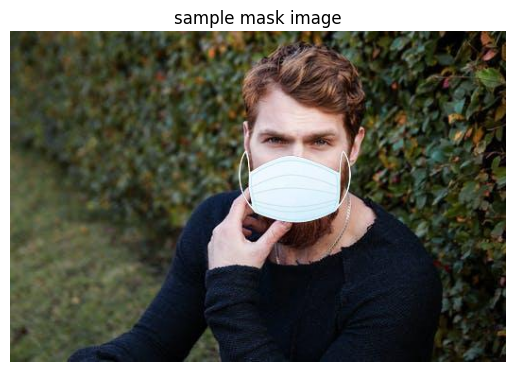

Image shape: (350, 525, 3)


In [18]:
plt.imshow(image_rgb)
plt.axis("off")
plt.title("sample mask image")
plt.show()
print("Image shape:",image.shape)

In [19]:
import cv2
import os
from skimage.feature import hog
import matplotlib.pyplot as plt

In [20]:
mask_path="dataset/with_mask"

In [21]:
images=[f for f in os.listdir(mask_path)
        if f.lower().endswith((".jpg",".jpeg",".png"))
       ]

In [22]:
image_path=os.path.join(mask_path,images[0])

In [23]:
image=cv2.imread(image_path)
image=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
image=cv2.resize(image,(64,64))

In [28]:
features=hog(image,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm="L2-Hys")

In [29]:
print("image shape:",image.shape)
print("hog feature count:",len(features))
print("first 10 feature:",features[:10])

image shape: (64, 64)
hog feature count: 1764
first 10 feature: [0.23586101 0.07854106 0.20713058 0.07336705 0.17961335 0.15594901
 0.1286136  0.23586101 0.06565612 0.23586101]


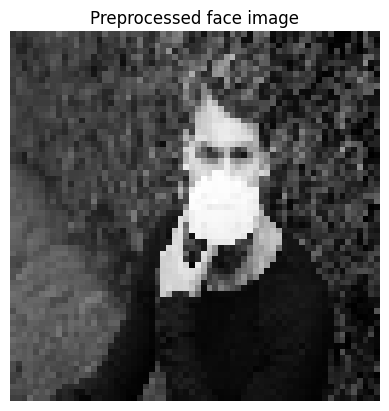

In [30]:
plt.imshow(image,cmap="gray")
plt.title("Preprocessed face image")
plt.axis("off")
plt.show()

In [33]:
import os
import cv2
import numpy as np
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import joblib

In [34]:
X=[]
y=[]

In [35]:
categories={
    "with_mask":1,
    "without_mask":0
}

In [38]:
for folder,label in categories.items():
    path=os.path.join("dataset",folder)
    for filename in os.listdir(path):
        if not filename.lower().endswith((".jpg",".jpeg",".png")):
            continue
        image_path=os.path.join(path,filename)
        image=cv2.imread(image_path)
        if image is None:
            continue
        gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
        gray=cv2.resize(gray,(64,64))
        features=hog(gray,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm="L2-Hys")
        X.append(features)
        y.append(label)
X=np.array(X)
y=np.array(y)
print("Total image processed:",len(X))
print("Feature matrix sahpe:",X.shape)
print("Labels shape:",y.shape)
      
            

Total image processed: 7553
Feature matrix sahpe: (7553, 1764)
Labels shape: (7553,)


In [39]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [41]:
print("Training images:",len(X_train))
print("Testing images:",len(X_test))

Training images: 6042
Testing images: 1511


In [42]:
model=SVC(kernel='linear',probability=True,random_state=42)


In [43]:
print("Training started.... Please wait")
model.fit(X_train,y_train)
print("SVM model training completed")

Training started.... Please wait


C:\Users\Nandani\anaconda3\anaconda\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM model training completed


In [44]:
y_pred=model.predict(X_test)

In [45]:
accuracy=accuracy_score(y_test,y_pred)
print(f"Model accuracy:{accuracy*100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["without Mask","With Mask"]))
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))

Model accuracy:83.59%

Classification Report:
              precision    recall  f1-score   support

without Mask       0.84      0.83      0.84       766
   With Mask       0.83      0.84      0.83       745

    accuracy                           0.84      1511
   macro avg       0.84      0.84      0.84      1511
weighted avg       0.84      0.84      0.84      1511

Confusion Matrix:
[[636 130]
 [118 627]]


In [46]:
os.makedirs("models",exist_ok=True)
joblib.dump(model,"models/mask_svm.pkl")
print("Model saved successfully!")
print("Location:models/mask_svm.pkl")

Model saved successfully!
Location:models/mask_svm.pkl


In [47]:
import cv2
import os

In [53]:
cascade_path=cv2.data.haarcascades+"harrcascade_frontalface_default.xml"
face_detector=cv2.CascadeClassifier(cascade_path)
if face_detector.empty():
    print("Face detector is not loaded")
else:
    print("opencv face detector loaded successfully")
                                    

Face detector is not loaded


In [54]:
cascade_path=cv2.data.haarcascades+"harrcascade_frontalface_default.xml"
print("Cascade path:",cascade_path)
print("File exists:",os.path.exists(cascade_path))

Cascade path: C:\Users\Nandani\anaconda3\anaconda\Lib\site-packages\cv2\data\harrcascade_frontalface_default.xml
File exists: False


In [55]:
face_detector=cv2.CascadeClassifier(cascade_path)
print("Detector empty:",face_detector.empty())

Detector empty: True


In [56]:
import cv2
import os

cascade_path = "haarcascade_frontalface_default.xml"

face_detector = cv2.CascadeClassifier(cascade_path)

print("File exists:", os.path.exists(cascade_path))
print("Detector empty:", face_detector.empty())

File exists: False
Detector empty: True


In [57]:
import urllib.request
import os

cascade_path = os.path.join(
    os.getcwd(),
    "haarcascade_frontalface_default.xml"
)

url = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml"

urllib.request.urlretrieve(url, cascade_path)

print("File downloaded:", os.path.exists(cascade_path))
print("Saved at:", cascade_path)

File downloaded: True
Saved at: C:\Users\Nandani\face_mask_detection\haarcascade_frontalface_default.xml


In [58]:
import cv2
import os

cascade_path = os.path.join(
    os.getcwd(),
    "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(cascade_path)

print("File exists:", os.path.exists(cascade_path))
print("Detector empty:", face_detector.empty())

File exists: True
Detector empty: False
